<a href="https://colab.research.google.com/github/DANFELcode/IAIA-preparcial-estudio_2corte/blob/main/binary_classification_rice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación binaria

En este notebook, realizarás las siguientes tareas:
- Analizarás un conjunto de datos que contiene mediciones derivadas de imágenes de dos especies de arroz turco.
- Crearás un clasificador binario para clasificar los granos de arroz en las dos especies.
- Evaluarás el desempeño del modelo.

## Objetivos de aprendizaje

Al completarlo, aprenderás:
- Cómo entrenar un clasificador binario.
- Cómo calcular métricas para un clasificador binario con diferentes umbrales.
- Cómo comparar el AUC y la curva ROC de dos modelos diferentes.

## Conjunto de datos

Este notebook utiliza el conjunto de datos de arroz de Osmancik y Cammeo de Cinar y Koklu (2019).

Se proporciona bajo una licencia CC0 (ver [Kaggle](https://www.kaggle.com/datasets/muratkokludataset/rice-dataset-commeo-and-osmancik) para obtener más información; las longitudes y el área se expresan en píxeles). Cinar y Koklu también ofrecen conjuntos de datos para clasificación multiclase (5 especies de arroz), pistaches, pasas, hojas de uva, entre otros, en su [repositorio](https://www.muratkoklu.com/datasets/).

### Cita

Cinar, I. and Koklu, M., (2019). “Classification of Rice Varieties Using Artificial Intelligence Methods.” *International Journal of Intelligent Systems and Applications in Engineering*, 7(3), 188-194.

DOI: https://doi.org/10.18201/ijisae.2019355381


# Cargar librerias

In [1]:
# @title Instalando librerias
!curl -LsSf https://astral.sh/uv/install.sh | sh
!uv init
!uv add keras matplotlib numpy pandas tensorflow

downloading uv 0.13.0 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!
Initialized project `content`
Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Resolved 43 packages in 1.29s
Prepared 42 packages in 1m 43s
Installed 42 packages in 889ms
 + absl-py==2.5.1
 + astunparse==1.6.3
 + certifi==2026.7.22
 + charset-normalizer==3.5.2
 + content==0.1.0 (from file:///content)
 + contourpy==1.4.0
 + cycler==0.12.1
 + flatbuffers==25.12.19
 + fonttools==4.66.1
 + gast==0.7.0
 + google-pasta==0.2.0
 + grpcio==1.84.0
 + h5py==3.14.0
 + idna==3.20
 + keras==3.15.1
 + kiwisolver==1.5.1
 + libclang==18.1.1
 + markdown-it-py==4.2.0
 + matplotlib==3.11.2
 + mdurl==0.1.2
 + ml-dtypes==0.6.0
 + namex==0.1.0
 + numpy==2.5.4
 + opt-einsum==3.4.0
 + optree==0.20.0
 + packaging==26.3
 + pandas==3.0.6
 + pillow==12.3.0
 + protobuf==7.36.2
 + pygments==2.21.0
 + pyparsing==3.3.3
 + python-dateutil==2.9.0.post0
 + requests==2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [3]:
# @title Crgar el conjunto de datos
rice_dataset_raw = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/Rice_Cammeo_Osmancik.csv")

Una vez que se haya cargado el conjunto de datos mediante la celda anterior, seleccione columnas específicas para mostrar estadísticas resumidas de las características numéricas del conjunto de datos.

Consulta la [documentación del conjunto de datos](https://www.kaggle.com/datasets/muratkokludataset/rice-dataset-commeo-and-osmancik) de Kaggle, especialmente la sección **Provenance**, para obtener explicaciones sobre el significado de cada característica y cómo se calcularon.

In [4]:
# @title Lea el conjunto de datos y proporcione estadísticas sobre él

#Lectura inicial
rice_dataset_raw.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.578979,229.749878,85.093788,0.928882,15617,0.572896,Cammeo
1,14656,494.311005,206.020065,91.730972,0.895405,15072,0.615436,Cammeo
2,14634,501.122009,214.106781,87.768288,0.912118,14954,0.693259,Cammeo
3,13176,458.342987,193.337387,87.448395,0.891861,13368,0.640669,Cammeo
4,14688,507.166992,211.743378,89.312454,0.906691,15262,0.646024,Cammeo


In [5]:
rice_dataset_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   int64  
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   int64  
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(5), int64(2), object(1)
memory usage: 238.3+ KB


In [10]:
rice_dataset_raw.columns

Index(['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length',
       'Eccentricity', 'Convex_Area', 'Extent', 'Class'],
      dtype='object')

In [11]:
rice_dataset_raw.describe()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000
mean,12667.727559,454.239180,188.776222,86.313750,0.886871,12952.496850,0.661934
std,1732.367706,35.597081,17.448679,5.729817,0.020818,1776.972042,0.077239
min,7551.000000,359.100006,145.264465,59.532406,0.777233,7723.000000,0.497413
25%,11370.500000,426.144753,174.353855,82.731695,0.872402,11626.250000,0.598862
50%,12421.500000,448.852493,185.810059,86.434647,0.889050,12706.500000,0.645361
75%,13950.000000,483.683746,203.550438,90.143677,0.902588,14284.000000,0.726562
max,18913.000000,548.445984,239.010498,107.542450,0.948007,19099.000000,0.861050


## Tarea 1: Describa los datos

A partir de las estadísticas resumidas anteriores, responda las siguientes preguntas:
- ¿Cuáles son las longitudes mínima y máxima (longitud del eje mayor, expresada en píxeles) de los granos de arroz?
- ¿Cuál es el rango de áreas entre el grano de arroz más pequeño y el más grande?
- ¿A cuántas desviaciones estándar (`std`) se encuentra el perímetro del grano de arroz más grande respecto a la media?

In [20]:
# @title Solución:

rice_dataset_raw["Major_Axis_Length"].max()


239.010498046875

In [19]:
rice_dataset_raw["Major_Axis_Length"].min()

145.264465332031

In [21]:
rice_dataset_raw["Area"].max() - rice_dataset_raw["Area"].min()

11362

In [22]:
perimetro = rice_dataset_raw["Perimeter"]
(perimetro.max() - perimetro.mean()) / perimetro.std()

np.float64(2.6464754951724068)

# Explore el conjunto de datos

Representa gráficamente algunas de las características, incluso en 3D.


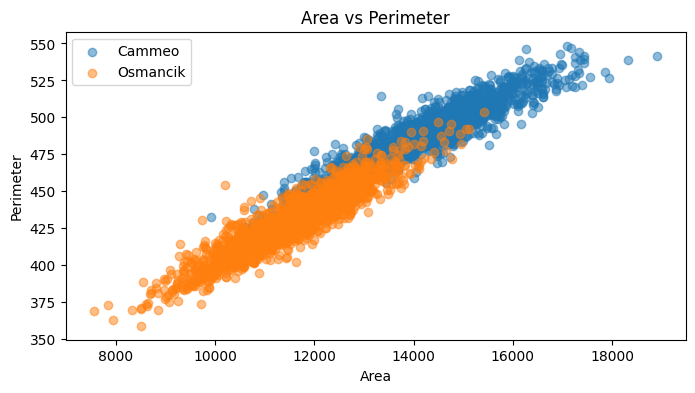

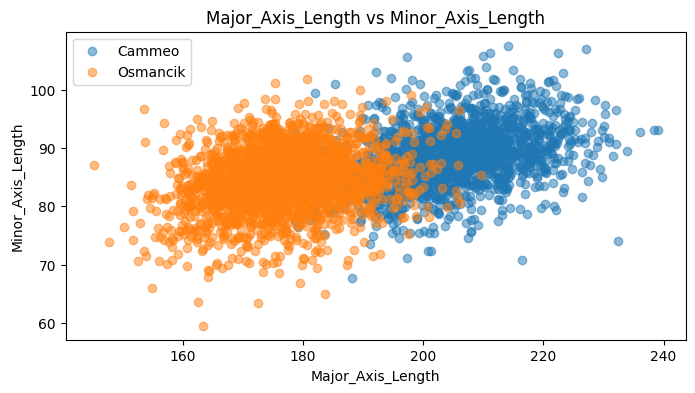

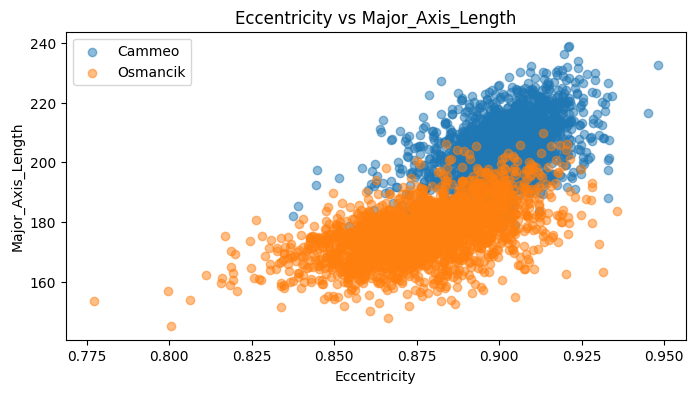

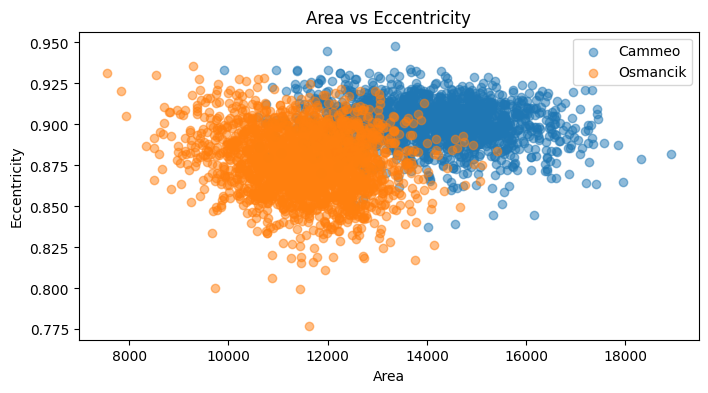

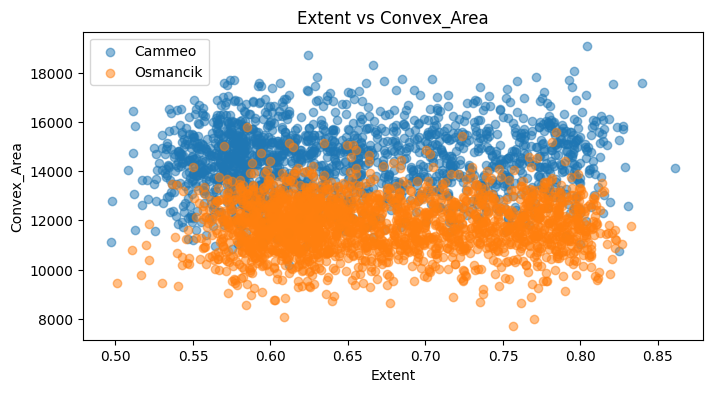

In [27]:
# Crea cinco gráficas bidimensionales en las que se representen las características unas frente a otras, codificadas por colores según su clase.

# Separar el dataset por clase
cammeo = rice_dataset_raw[rice_dataset_raw["Class"] == "Cammeo"]
osmancik = rice_dataset_raw[rice_dataset_raw["Class"] == "Osmancik"]

# 5 pares de características (eje X, eje Y)
pares = [
    ("Area", "Perimeter"),
    ("Major_Axis_Length", "Minor_Axis_Length"),
    ("Eccentricity", "Major_Axis_Length"),
    ("Area", "Eccentricity"),
    ("Extent", "Convex_Area"),
]

# Una gráfica por par
for x, y in pares:
    plt.figure(figsize=(8, 4))
    plt.scatter(cammeo[x], cammeo[y], alpha=0.5, label="Cammeo")
    plt.scatter(osmancik[x], osmancik[y], alpha=0.5, label="Osmancik")
    plt.title(f"{x} vs {y}")
    plt.xlabel(x)
    plt.ylabel(y)
    plt.legend()
    plt.show()

## Tarea 2: Visualizar muestras en 3D

Intente representar gráficamente tres de las características en 3D, comparandolas unas con otras.

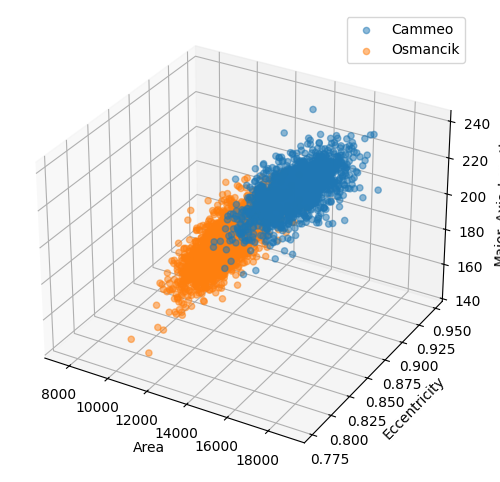

In [32]:
#@title Graficque tres caracteristicas en 3D


x_axis_data = 'Area'
y_axis_data = 'Eccentricity'
z_axis_data = 'Major_Axis_Length'

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# un scatter por clase, igual que antes, pero con 3 coordenadas
ax.scatter(cammeo[x_axis_data], cammeo[y_axis_data], cammeo[z_axis_data], alpha=0.5, label="Cammeo")
ax.scatter(osmancik[x_axis_data], osmancik[y_axis_data], osmancik[z_axis_data], alpha=0.5, label="Osmancik")

ax.set_xlabel(x_axis_data)
ax.set_ylabel(y_axis_data)
ax.set_zlabel(z_axis_data)
ax.legend()
plt.show()

1. ¿Qué variables diferencian mejor las dos clases de arroz?
2. ¿Qué variables diferencian mejor las dos clases de arroz?
3. Al graficar las variables por pares (o en 3D), ¿en qué combinaciones se solapan menos las clases?
4. Si solo pudiéramos usar tres variables, ¿cuáles concentran la mayor parte de la información para distinguir las clases?

## Normalizar datos

Al crear un modelo con múltiples características, los valores de cada una de ellas deben estar aproximadamente el mismo rango. Si los valores de una característica van de 500 a 100 000 y los de otra van de 2 a 12, el modelo necesitará tener pesos con valores extremadamente bajos o extremadamente altos para poder combinar estas características de manera efectiva. Esto podría dar lugar a un modelo de baja calidad.  Para evitarlo, debe
[normalizar](https://developers.google.com/machine-learning/glossary/#normalization) las características en un modelo con múltiples características.

Esto se puede hacer convirtiendo cada valor sin procesar en su Z-Score. El **Z-Score** de un valor dado representa cuántas desviaciones estándar se encuentra ese valor de la media.

Consideremos una característica con una media de 60 y una desviación estándar de 10.

El valor 75 tendría un Z-Score de +1,5:

```
  Z-score = (75 - 60) / 10 = +1.5
```

El valor 38 tendría un Z-Score de -2,2:

```
  Z-score = (38 - 60) / 10 = -2.2
```

Ahora normalice los valores numéricos del conjunto de datos sobre el arroz convirtiéndolos en valores Z-Score.

In [46]:
# Calcule las Z-Score de cada columna numérica de los datos sin procesar
numericas = rice_dataset_raw.select_dtypes(include="number")

# escribalas en un nuevo DataFrame llamado df_norm.

df_norm = (numericas - numericas.mean()) / numericas.std()

# Copie la columna objetivo al nuevo DataFrame

df_norm["Class"] = rice_dataset_raw["Class"]


# Observe algunos de los valores del conjunto de entrenamiento normalizado.

# Observe que la mayoría de los valores de la normalizacion Z-Score se encuentran entre -2 y +2.
df_norm.head()

normalized_dataset = df_norm



## Etiquetar y dividir los datos

Para entrenar el modelo, asignaremos arbitrariamente a la especie *Cammeo* la etiqueta "1" y a la especie *Osmancik* la etiqueta "0".

In [47]:
# Crea una columna en la que la etiqueta "Cammeo" se establezca en "1" y la etiqueta "Osmancik" en "0"
# luego, muestre 10 filas seleccionadas al azar.

df_norm["Target"] = df_norm["Class"].map({"Cammeo": 1, "Osmancik": 0})
df_norm.sample(10)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class,Target
934,0.885651,0.890489,0.793059,0.756836,0.358427,0.949651,-1.296866,Cammeo,1
1304,0.343618,0.945353,1.470130,-1.164549,1.998199,0.303045,0.162004,Cammeo,1
205,1.038043,1.224842,0.895960,0.855356,0.386458,1.087526,-0.070341,Cammeo,1
1060,0.332650,0.216305,0.309911,0.263056,0.240999,0.294604,0.638852,Cammeo,1
3291,-0.640007,-0.764366,-0.890523,0.152749,-1.092988,-0.626063,0.481793,Osmancik,0
3564,-0.788359,-1.012392,-1.215058,0.112165,-1.539169,-0.766189,-0.496841,Osmancik,0
1633,-0.454134,-0.422905,-0.280061,-0.517343,0.216579,-0.481435,-1.024143,Osmancik,0
645,1.459432,1.233410,1.344946,0.935988,0.722048,1.392539,0.658010,Cammeo,1
2762,0.048646,0.031261,0.171131,-0.110575,0.372823,-0.008158,-1.159143,Osmancik,0
744,0.586061,1.026877,1.232514,-0.395951,1.430768,0.694723,1.449937,Cammeo,1


A continuación, puede selecionar aleatoriamente y dividir el conjunto de datos en subconjuntos de **entrenamiento**, **validación** y **prueba**, que representan el 80 %, el 10 % y el 10 % del conjunto de datos, respectivamente.

Utilizaremos los datos de entrenamiento para aprender los parámetros del modelo; luego, utilizaremos los datos de validación para evaluar diferentes modelos; y, por último, utilizaremos los datos de prueba para calcular las métricas finales del modelo que haya tenido el mejor desempeño en los datos de validación.

In [48]:
number_samples = len(normalized_dataset)
index_80th = round(number_samples * 0.8)
index_90th = index_80th + round(number_samples * 0.1)

# Divida en conjuntos de entrenamiento, validación y prueba con una proporción de 0,8, 0,1 y 0,1.
shuffled_dataset = normalized_dataset.sample(frac=1, random_state=100)

train_data = shuffled_dataset.iloc[:index_80th]
validation_data = shuffled_dataset.iloc[index_80th:index_90th]
test_data = shuffled_dataset.iloc[index_90th:]

print(len(train_data), len(validation_data), len(test_data))


# Mostrar las primeras cinco filas del conjunto de prueba

test_data.head()

3048 381 381


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class,Target
2405,-0.438549,-0.661183,-0.825462,0.313231,-1.149000,-0.444856,0.341663,Osmancik,0
3062,-0.197838,-0.005342,0.224592,-0.656363,0.802824,-0.207936,1.606695,Osmancik,0
1155,1.381504,1.211330,1.081698,1.176669,0.340787,1.336264,0.710095,Cammeo,1
660,1.165037,1.016005,0.817115,1.311436,-0.002803,1.188822,-0.611756,Cammeo,1
2451,-1.154909,-1.193698,-1.423946,-0.278183,-1.477920,-1.106093,0.053997,Osmancik,0


Es importante evitar que el modelo reciba la etiqueta como entrada durante el entrenamiento, lo que se conoce como “fuga de etiquetas”. Esto se puede lograr almacenando las características y las etiquetas como variables separadas.

In [49]:
# Separe los conjuntos en 2 partes uno que contendrá las caracteristicas de entrada
# otro que contrendrá las etiquetas o valores de verdad

# Features: se quita Class y Target
train_features = train_data.drop(columns=["Class", "Target"])
validation_features = validation_data.drop(columns=["Class", "Target"])
test_features = test_data.drop(columns=["Class", "Target"])

# Etiquetas: solo Target
train_labels = train_data["Target"]
validation_labels = validation_data["Target"]
test_labels = test_data["Target"]

## Entrenar el modelo

### Elegir las características de entrada

Para empezar, entrene un modelo con `Eccentricity`, `Longitud del Major_Axis_Length mayor` y `Area`.

In [51]:
# Nombre de las características con las que entrenará su modelo.

input_features = ["Eccentricity", "Major_Axis_Length", "Area"]

Continue su aprendizaje seleccionando metricas y mostrandolas en una grafica despues de realizar el entrenamiento

In [52]:
# 2. Modelo: una neurona con sigmoide (probabilidad de ser Cammeo)
model = keras.Sequential([
    layers.Input(shape=(len(input_features),)),
    layers.Dense(1, activation="sigmoid")
])

# 3. Compilar
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")]
)

# 4. Entrenar
history = model.fit(
    train_features[input_features], train_labels,
    validation_data=(validation_features[input_features], validation_labels),
    epochs=20, batch_size=32
)

Epoch 1/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1132 - auc: 0.0399 - loss: 1.3743 - precision: 0.0765 - recall: 0.0963 - val_accuracy: 0.1522 - val_auc: 0.0642 - val_loss: 1.2789 - val_precision: 0.1111 - val_recall: 0.1302
Epoch 2/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1473 - auc: 0.0547 - loss: 1.2202 - precision: 0.0828 - recall: 0.0978 - val_accuracy: 0.1969 - val_auc: 0.0888 - val_loss: 1.1395 - val_precision: 0.1215 - val_recall: 0.1302
Epoch 3/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1909 - auc: 0.0859 - loss: 1.0819 - precision: 0.0980 - recall: 0.1077 - val_accuracy: 0.2467 - val_auc: 0.1350 - val_loss: 1.0151 - val_precision: 0.1529 - val_recall: 0.1538
Epoch 4/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2592 - auc: 0.1469 - loss: 0.9603 - precision: 0.1342 - recall: 0.1329 - val_accuracy: 0.3176 - val_auc: 0.2124 - val_loss: 0.9060 - val_precision: 0.2102 - val_recall: 0.1953
Epoch 5/20
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s

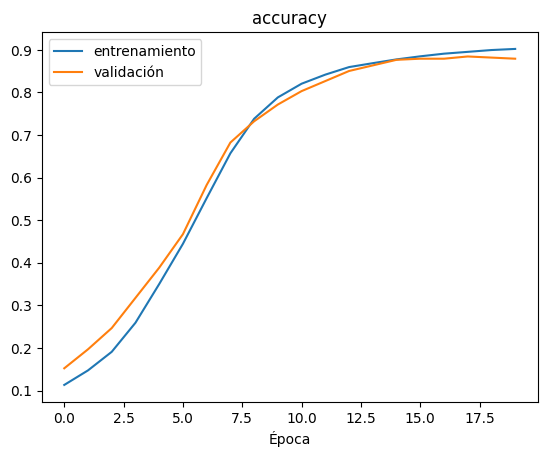

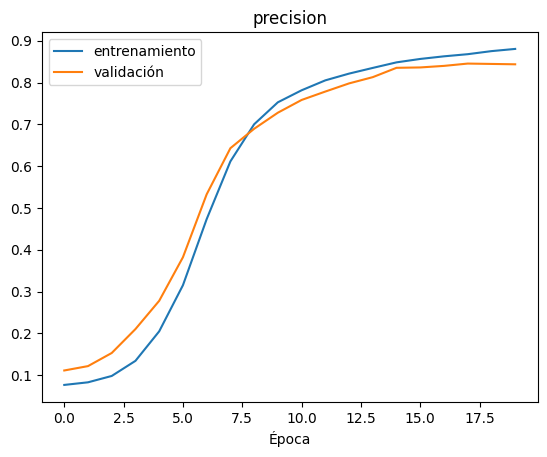

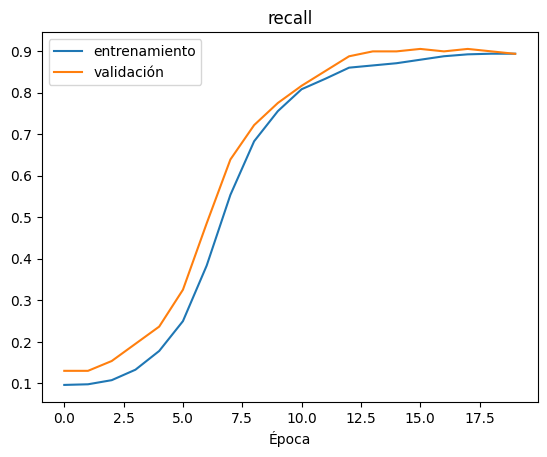

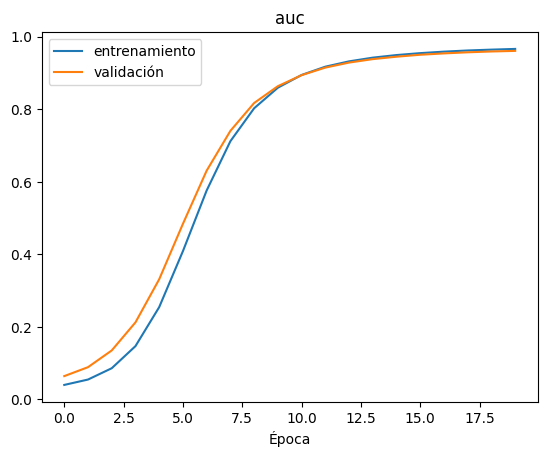

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8845 - auc: 0.9596 - loss: 0.3107 - precision: 0.8462 - recall: 0.8684 


[0.3107433021068573,
 0.8845144510269165,
 0.8461538553237915,
 0.8684210777282715,
 0.959578275680542]

In [53]:
# 5. Graficar métricas por época
for metrica in ["accuracy", "precision", "recall", "auc"]:
    plt.plot(history.history[metrica], label="entrenamiento")
    plt.plot(history.history["val_" + metrica], label="validación")
    plt.title(metrica)
    plt.xlabel("Época")
    plt.legend()
    plt.show()

# 6. Métricas finales en el conjunto de prueba
model.evaluate(test_features[input_features], test_labels)